<a href="https://colab.research.google.com/github/haroonahmadg/Churn-detection-ML/blob/main/Churn_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install huggingface_hub pyarrow

In [ ]:
pip install imbalanced-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.1/236.1 kB 9.6 MB/s eta 0:00:00


**Importing Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

**Loading Dataset From Hugging-Face**

In [ ]:
from huggingface_hub import hf_hub_download
file_path = hf_hub_download(
    repo_id="electricsheepafrica/africa-financial-inclusion-nigeria",
    filename="nigerian_mobile_money_full.parquet",
    repo_type="dataset"
)
# Open it directly into pandas
df = pd.read_parquet(file_path)
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
df.replace("", np.nan, inplace=True)
print("Dataset successfully fetched from the correct repository!")
print(f"Total rows loaded: {len(df)}")

nigerian_mobile_money_full.parquet: reconstructing file:   0%|          |  0.00B /  248MB            

nigerian_mobile_money_full.parquet: downloading bytes:           |  0.00B            

Dataset successfully fetched from the correct repository!
Total rows loaded: 4000000


# ***Exploratory Data Analysis (EDA)***

**Understand the Dataset**

In [ ]:
df

,transaction_id,wallet_id,timestamp,transaction_type,amount_ngn,fee_ngn,balance_after_ngn,agent_id,channel,device_os,kyc_tier,fraud_flag,churn_30d
0,90e956c0-7e3e-4207-8bbc-90de4c61d05e,WLT-00001530,2024-06-03 20:35:00,airtime,1000.0,10.0,917.204594,NaN,ussd,android,tier2,False,False
1,3cff1814-4796-4e7e-91ff-2cc1240fe8d8,WLT-00001003,2024-04-01 08:34:00,cashin,1150.0,10.0,644.741704,AGT-00004700,ussd,android,tier2,False,False
2,9fb30da5-5e4e-453f-86cc-3cf842d211ac,WLT-00018460,2024-01-08 19:17:00,cashout,4850.0,10.0,3582.585292,AGT-00001615,app,android,tier1,False,False
3,6127f44f-6d23-4d9f-988f-54dcae598f4d,WLT-00000072,2024-04-14 23:10:00,p2p_send,9800.0,98.0,1546.044463,NaN,ussd,android,tier3,False,False
4,f5ca608d-9ddb-40ca-a4ad-39c8474477cd,WLT-00017907,2024-06-14 07:10:00,billpay,1600.0,10.0,4361.698947,NaN,app,feature_phone,tier2,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3999995,67a93d88-9dcf-4e64-a3cc-ab1259fa5814,WLT-00000581,2024-03-18 13:15:00,airtime,1500.0,10.0,15480.832350,NaN,ussd,android,tier1,False,True
3999996,226993ef-842f-48c5-b7a8-390cddbd61e9,WLT-00000004,2024-06-12 15:56:00,p2p_send,4350.0,10.0,7868.921789,NaN,ussd,android,tier2,False,False
3999997,e3197893-3164-4d1f-bfa2-c4b6b2420565,WLT-00000004,2024-02-15 19:41:00,cashin,900.0,10.0,4300.846308,AGT-00009113,ussd,android,tier2,False,False
3999998,88aac47f-ca20-42b2-a404-0177421c8832,WLT-00001215,2024-04-15 15:36:00,p2p_send,250.0,10.0,8594.218758,NaN,app,ios,tier1,False,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000000 entries, 0 to 3999999
Data columns (total 13 columns):
 #   Column             Dtype         
---  ------             -----         
 0   transaction_id     object        
 1   wallet_id          object        
 2   timestamp          datetime64[ns]
 3   transaction_type   object        
 4   amount_ngn         float64       
 5   fee_ngn            float64       
 6   balance_after_ngn  float64       
 7   agent_id           object        
 8   channel            object        
 9   device_os          object        
 10  kyc_tier           object        
 11  fraud_flag         bool          
 12  churn_30d          bool          
dtypes: bool(2), datetime64[ns](1), float64(3), object(7)
memory usage: 343.3+ MB


In [ ]:
df.head()


,transaction_id,wallet_id,timestamp,transaction_type,amount_ngn,fee_ngn,balance_after_ngn,agent_id,channel,device_os,kyc_tier,fraud_flag,churn_30d
0,90e956c0-7e3e-4207-8bbc-90de4c61d05e,WLT-00001530,2024-06-03 20:35:00,airtime,1000.0,10.0,917.204594,NaN,ussd,android,tier2,False,False
1,3cff1814-4796-4e7e-91ff-2cc1240fe8d8,WLT-00001003,2024-04-01 08:34:00,cashin,1150.0,10.0,644.741704,AGT-00004700,ussd,android,tier2,False,False
2,9fb30da5-5e4e-453f-86cc-3cf842d211ac,WLT-00018460,2024-01-08 19:17:00,cashout,4850.0,10.0,3582.585292,AGT-00001615,app,android,tier1,False,False
3,6127f44f-6d23-4d9f-988f-54dcae598f4d,WLT-00000072,2024-04-14 23:10:00,p2p_send,9800.0,98.0,1546.044463,NaN,ussd,android,tier3,False,False
4,f5ca608d-9ddb-40ca-a4ad-39c8474477cd,WLT-00017907,2024-06-14 07:10:00,billpay,1600.0,10.0,4361.698947,NaN,app,feature_phone,tier2,False,False


In [ ]:
df.tail()

,transaction_id,wallet_id,timestamp,transaction_type,amount_ngn,fee_ngn,balance_after_ngn,agent_id,channel,device_os,kyc_tier,fraud_flag,churn_30d
3999995,67a93d88-9dcf-4e64-a3cc-ab1259fa5814,WLT-00000581,2024-03-18 13:15:00,airtime,1500.0,10.0,15480.832350,NaN,ussd,android,tier1,False,True
3999996,226993ef-842f-48c5-b7a8-390cddbd61e9,WLT-00000004,2024-06-12 15:56:00,p2p_send,4350.0,10.0,7868.921789,NaN,ussd,android,tier2,False,False
3999997,e3197893-3164-4d1f-bfa2-c4b6b2420565,WLT-00000004,2024-02-15 19:41:00,cashin,900.0,10.0,4300.846308,AGT-00009113,ussd,android,tier2,False,False
3999998,88aac47f-ca20-42b2-a404-0177421c8832,WLT-00001215,2024-04-15 15:36:00,p2p_send,250.0,10.0,8594.218758,NaN,app,ios,tier1,False,False
3999999,03c6a877-9685-4115-9772-d2ef68592f28,WLT-00000001,2024-02-28 09:07:00,p2p_send,2750.0,10.0,18509.747707,NaN,ussd,feature_phone,tier2,False,False


In [ ]:
df.sample()

,transaction_id,wallet_id,timestamp,transaction_type,amount_ngn,fee_ngn,balance_after_ngn,agent_id,channel,device_os,kyc_tier,fraud_flag,churn_30d
2938515,60599539-44e8-4559-96c9-7ecbb0ddf9eb,WLT-00095605,2024-04-13 16:49:00,p2p_send,39500.0,200.0,14859.093814,NaN,app,android,tier1,False,False


In [ ]:
df.shape

(4000000, 13)

In [ ]:
df["fraud_flag"]=df["fraud_flag"].astype(int)

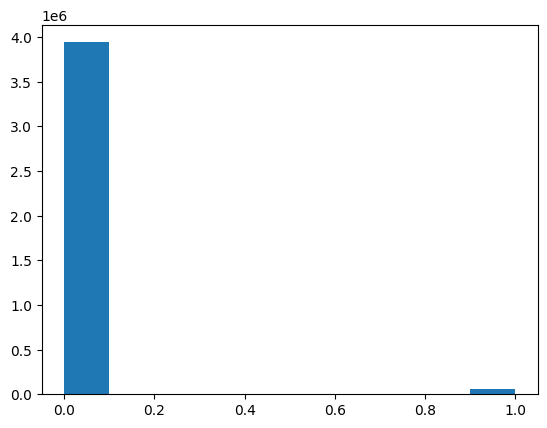

In [ ]:
plt.hist(df["fraud_flag"])
plt.show()

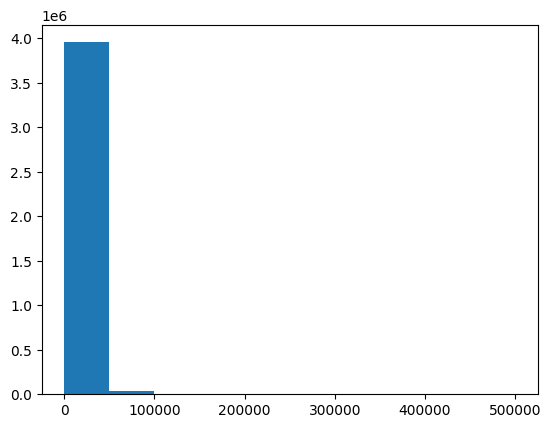

In [ ]:
plt.hist(df["amount_ngn"])
plt.show()

In [ ]:
churn=df["churn_30d"].astype(int)
print(churn)

0          0
1          0
2          0
3          0
4          0
          ..
3999995    1
3999996    0
3999997    0
3999998    0
3999999    0
Name: churn_30d, Length: 4000000, dtype: int64


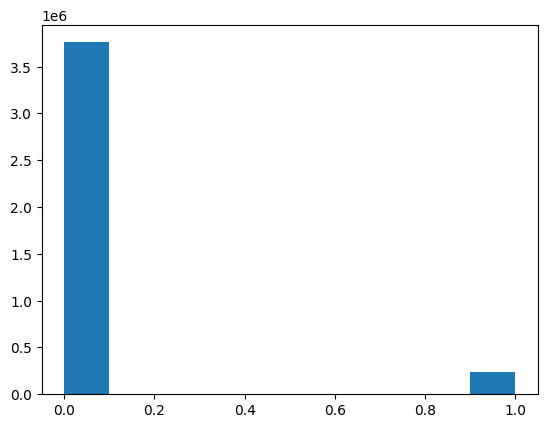

In [ ]:
plt.hist(churn)
plt.show()

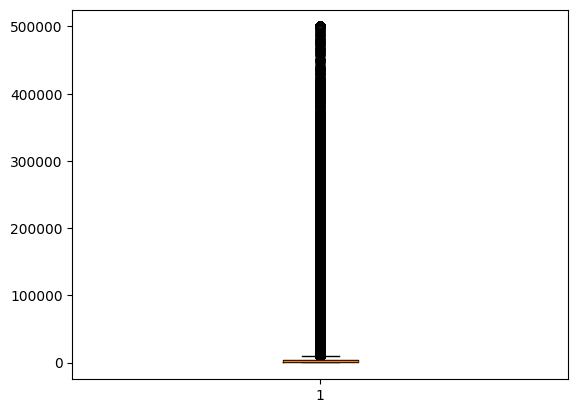

In [ ]:
plt.boxplot(df["amount_ngn"])
plt.show()

**Data cleaning**

In [ ]:
df.describe()

,timestamp,amount_ngn,fee_ngn,balance_after_ngn,fraud_flag
count,4000000,4.000000e+06,4.000000e+06,4.000000e+06,4.000000e+06
mean,2024-03-31 14:28:19.668344832,5.011743e+03,3.431395e+01,1.334904e+04,1.500000e-02
min,2024-01-01 00:01:00,5.000000e+01,1.000000e+01,4.479525e+01,0.000000e+00
25%,2024-02-15 10:33:00,7.500000e+02,1.000000e+01,4.126032e+03,0.000000e+00
50%,2024-03-31 15:18:00,1.650000e+03,1.000000e+01,8.096005e+03,0.000000e+00
75%,2024-05-15 18:29:00,4.300000e+03,1.000000e+01,1.588577e+04,0.000000e+00
max,2024-06-29 23:59:00,5.000000e+05,2.000000e+02,1.192877e+06,1.000000e+00
std,NaN,1.312389e+04,5.227146e+01,1.746935e+04,1.215525e-01


In [ ]:
df["transaction_id"].drop_duplicates(inplace=True)

In [ ]:
df["transaction_type"].drop_duplicates(keep="last",inplace=True)

In [ ]:
df.drop_duplicates(keep="last", inplace=True)

In [ ]:
df.isnull().sum()

,0
transaction_id,0
wallet_id,0
timestamp,0
transaction_type,0
amount_ngn,0
fee_ngn,0
balance_after_ngn,0
agent_id,3278910
channel,0
device_os,0


In [ ]:
print(df.isnull().sum())

transaction_id             0
wallet_id                  0
timestamp                  0
transaction_type           0
amount_ngn                 0
fee_ngn                    0
balance_after_ngn          0
agent_id             3278910
channel                    0
device_os                  0
kyc_tier                   0
fraud_flag                 0
churn_30d                  0
dtype: int64


In [ ]:
df["agent_id"].isnull().sum()

np.int64(3278910)

In [ ]:
print(df.isnull().sum())

transaction_id             0
wallet_id                  0
timestamp                  0
transaction_type           0
amount_ngn                 0
fee_ngn                    0
balance_after_ngn          0
agent_id             3278910
channel                    0
device_os                  0
kyc_tier                   0
fraud_flag                 0
churn_30d                  0
dtype: int64


In [ ]:
df["amount_ngn"].max()

np.float64(500000.0)

In [ ]:
df["amount_ngn"].min()


np.float64(50.0)

In [ ]:
df["amount_ngn"].mode()

,amount_ngn
0,500.0


**Data Visualization**

--- Group Breakdown ---
amount_ngn    churn_30d
Low Value     False        941104
              True          92952
Medium Value  False        888392
              True          92043
High Value    False        938644
              True          49015
Top Tier      False        991860
              True           5990
Name: count, dtype: int64


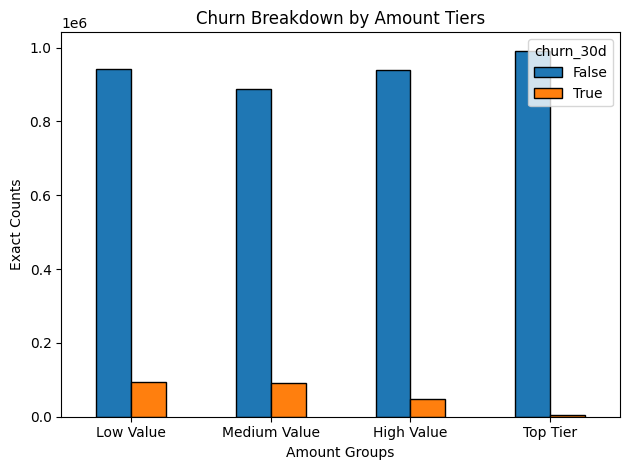

In [ ]:
# 1. Clean the column data
df["amount_ngn"] = pd.to_numeric(df["amount_ngn"], errors="coerce").fillna(0)
bin_labels = ["Low Value", "Medium Value", "High Value", "Top Tier"]

# 2. FIXED LINE: Pay close attention to where the parentheses close!
grouped_analysis = df.groupby(
    pd.qcut(df["amount_ngn"], q=4, labels=bin_labels, duplicates="drop"),
    observed=False,  # <-- It must sit out here, inside groupby()!
)["churn_30d"].value_counts()

# 3. Print the results
print("--- Group Breakdown ---")
print(grouped_analysis)

# 4. Plot the clean bar chart
ax = grouped_analysis.unstack().plot(kind="bar", edgecolor="black")
#plt.yscale("log")

plt.title("Churn Breakdown by Amount Tiers")
plt.xlabel("Amount Groups")
plt.ylabel("Exact Counts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


kyc_tier  churn_30d
tier1     False        2106204
          True          233991
tier2     False        1443079
          True            5199
tier3     False         210717
          True             810
Name: count, dtype: int64


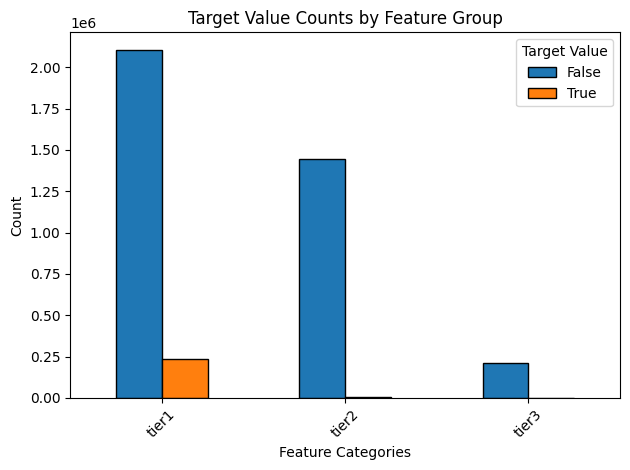

In [ ]:
gb1=df.groupby("kyc_tier")["churn_30d"].value_counts()
print(gb1)
gb1.unstack().plot(kind="bar", edgecolor="black")

# 4. Customize and display the plot
plt.title("Target Value Counts by Feature Group")
plt.xlabel("Feature Categories")
plt.ylabel("Count")
plt.legend(title="Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

channel  churn_30d
agent    False         487285
         True           31011
app      False        1314691
         True           84552
ussd     False        1883178
         True          119734
web      False          74846
         True            4703
Name: count, dtype: int64


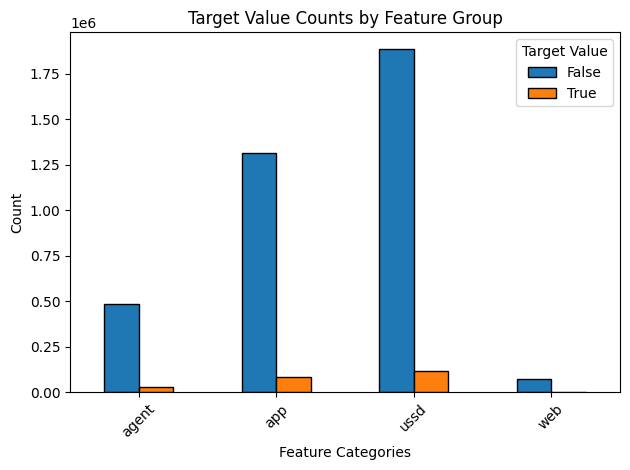

In [ ]:
gb2=df.groupby("channel")["churn_30d"].value_counts()
print(gb2)
gb2.unstack().plot(kind="bar", edgecolor="black")

# 4. Customize and display the plot
plt.title("Target Value Counts by Feature Group")
plt.xlabel("Feature Categories")
plt.ylabel("Count")
plt.legend(title="Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

device_os      churn_30d
android        False        2631752
               True          167959
feature_phone  False         939898
               True           60212
ios            False         188350
               True           11829
Name: count, dtype: int64


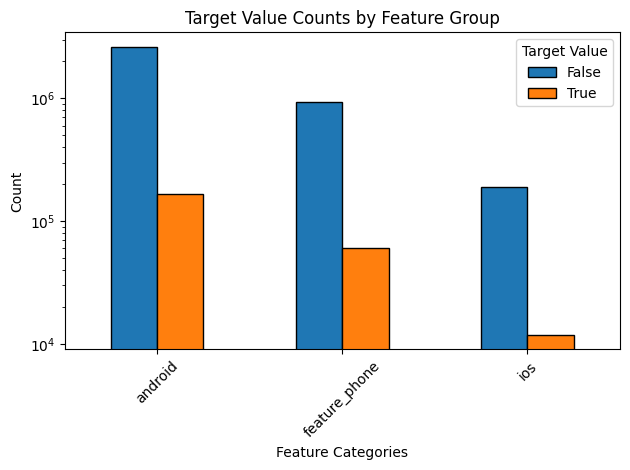

In [ ]:
gb2=df.groupby("device_os")["churn_30d"].value_counts()
print(gb2)
gb2.unstack().plot(kind="bar", edgecolor="black")

# 4. Show the chart
plt.yscale("log")
# 4. Customize and display the plot
plt.title("Target Value Counts by Feature Group")
plt.xlabel("Feature Categories")
plt.ylabel("Count")
plt.legend(title="Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

transaction_type  churn_30d
airtime           False        775822
                  True         222295
billpay           False        596723
                  True           3652
cashin            False        398413
                  True           2376
cashout           False        318394
                  True           1907
data              False         80198
                  True            421
p2p_receive       False        794750
                  True           4593
p2p_send          False        795700
                  True           4756
Name: count, dtype: int64


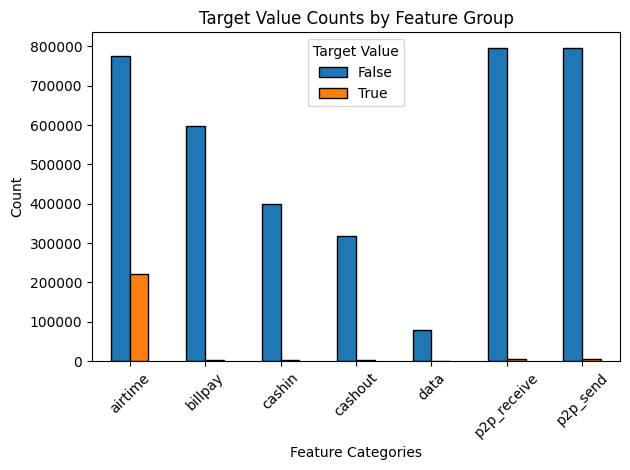

In [ ]:
gb2=df.groupby("transaction_type")["churn_30d"].value_counts()
print(gb2)
gb2.unstack().plot(kind="bar", edgecolor="black")
#plt.yscale("log")
# 4. Customize and display the plot
plt.title("Target Value Counts by Feature Group")
plt.xlabel("Feature Categories")
plt.ylabel("Count")
plt.legend(title="Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df["fee_ngn"].max()

np.float64(200.0)

In [ ]:
df["fee_ngn"].min()

np.float64(10.0)

In [ ]:
# Returns an array of distinct elements
df['fee_ngn'].unique()


array([ 10. ,  98. ,  52. ,  69. , 111. ,  53.5, 141. , 200. ,  51. ,
        75.5,  65.5,  57. ,  68.5, 175.5,  95.5, 163.5, 131.5,  92.5,
       100.5,  96.5, 124.5,  58. ,  79. ,  85. , 165.5, 112. , 126. ,
        68. ,  50. , 105.5, 164.5, 144. ,  93. , 115.5, 138. , 118.5,
        60. , 152.5, 140. , 117.5,  66. , 182.5, 179.5,  64. ,  73.5,
       157.5,  90. ,  56.5, 132. ,  81.5,  61.5,  83.5, 181.5,  55.5,
       119.5, 143. , 118. ,  79.5,  76.5, 123. , 145. ,  97.5, 102.5,
        52.5, 134. ,  80. ,  57.5,  92. ,  56. ,  89. ,  63.5,  62.5,
       115. ,  67. , 196.5,  85.5,  87. ,  78. , 185.5,  51.5,  73. ,
       129. ,  84.5,  94.5,  50.5,  54.5, 194.5, 139.5, 103.5,  77. ,
        62. , 127. ,  72.5, 100. ,  74. , 113.5,  71. ,  97. ,  70. ,
       189. ,  98.5,  59.5, 149. ,  59. ,  58.5,  81. , 184. , 117. ,
        53. , 177.5, 170. ,  82. , 131. , 168.5, 109.5,  64.5, 158.5,
       179. ,  61. , 162. , 193. ,  65. ,  70.5,  82.5, 128. , 174.5,
        90.5, 135. ,

fee_ngn  churn_30d
10.0     False        2872657
         True          234644
50.0     False           7255
         True              34
50.5     False           7268
                       ...   
199.0    True               3
199.5    False            645
         True               3
200.0    False         193113
         True            1153
Name: count, Length: 604, dtype: int64


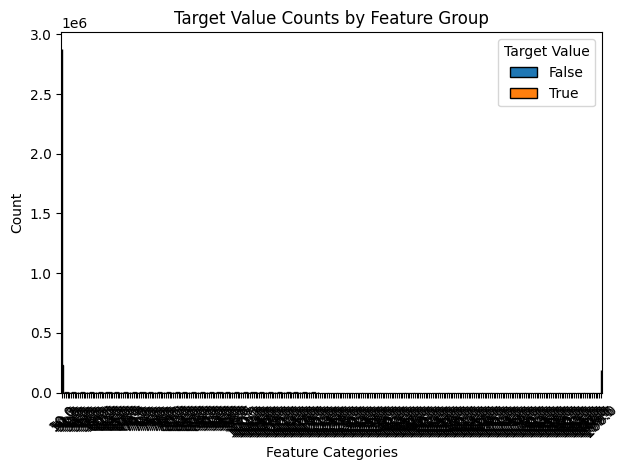

In [ ]:
gb3=df.groupby("fee_ngn")["churn_30d"].value_counts()
print(gb3)
gb3.unstack().plot(kind="bar", edgecolor="black")
#plt.yscale("log")
# 4. Customize and display the plot
plt.title("Target Value Counts by Feature Group")
plt.xlabel("Feature Categories")
plt.ylabel("Count")
plt.legend(title="Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Imbalance Data Of Features**

In [ ]:
print(df['churn_30d'].value_counts())

ratio = df['churn_30d'].value_counts().max() / df['churn_30d'].value_counts().min()

print("Imbalance Ratio:", ratio)

churn_30d
False    3760000
True      240000
Name: count, dtype: int64
Imbalance Ratio: 15.666666666666666


In [ ]:
print(df['churn_30d'].value_counts(normalize=True) * 100)

churn_30d
False    94.0
True      6.0
Name: proportion, dtype: float64


In [ ]:
class_counts = df['churn_30d'].value_counts()

majority = class_counts.max()
minority = class_counts.min()

ratio = majority / minority

print(f"Imbalance Ratio: {ratio:.2f}:1")

Imbalance Ratio: 15.67:1


In [ ]:
class_counts = df['fraud_flag'].value_counts()

majority = class_counts.max()
minority = class_counts.min()

ratio = majority / minority

print(f"Imbalance Ratio: {ratio:.2f}:1")

Imbalance Ratio: 65.67:1


In [ ]:
df.drop(columns=["agent_id","transaction_id","wallet_id","timestamp","fraud_flag","fee_ngn"], inplace=True)

In [ ]:
column=df.columns
print(column)

Index(['transaction_type', 'amount_ngn', 'balance_after_ngn', 'channel',
       'device_os', 'kyc_tier', 'churn_30d'],
      dtype='object')


# Separate Target Variable From Dataset

In [ ]:
y=df["churn_30d"]
X=df.drop(columns=["churn_30d"])


In [ ]:
y=y.astype(int)

**Test and Train split**

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(x_train)

        transaction_type  amount_ngn  balance_after_ngn channel  \
2088093      p2p_receive       200.0        7158.694663    ussd   
96291           p2p_send      6950.0       12273.040321     app   
113546       p2p_receive      8900.0        1626.295769    ussd   
3702826         p2p_send      8050.0       31152.619850     app   
3689919          airtime      2000.0        3881.681185    ussd   
...                  ...         ...                ...     ...   
2356330             data       500.0        4884.200708    ussd   
3511566          airtime       200.0       16258.066667     app   
2229084          billpay     25300.0        2154.129360    ussd   
2768307          billpay      7100.0       37630.994520    ussd   
2219110      p2p_receive      4300.0       10143.431303    ussd   

             device_os kyc_tier  
2088093        android    tier1  
96291          android    tier2  
113546   feature_phone    tier3  
3702826  feature_phone    tier1  
3689919  feature_phone   

In [ ]:
print(x_test)

        transaction_type  amount_ngn  balance_after_ngn channel  \
1049554          airtime       200.0       12526.048442    ussd   
214510           airtime       200.0        9270.424824     app   
2145764          billpay      2550.0        6235.176425    ussd   
2198867           cashin       100.0       39951.111769     app   
1184366          airtime      2000.0        1532.980480     app   
...                  ...         ...                ...     ...   
3257093          airtime      1500.0        8340.728699    ussd   
1973002          airtime      1000.0       10283.709215    ussd   
3250857      p2p_receive      1650.0        9692.544998   agent   
972218           airtime      1500.0        5243.008502     app   
3794902         p2p_send      1100.0        4992.204239    ussd   

             device_os kyc_tier  
1049554  feature_phone    tier1  
214510   feature_phone    tier1  
2145764        android    tier1  
2198867        android    tier1  
1184366        android   

**Separate the numerical and categorical columns**

In [ ]:
categorical_columns=['transaction_type', 'channel', 'device_os', 'kyc_tier']
numerical_columns=['balance_after_ngn',"amount_ngn"]

In [ ]:
print(categorical_columns)

['transaction_type', 'channel', 'device_os', 'kyc_tier']


In [ ]:
print(y_test)

1049554    0
214510     0
2145764    0
2198867    0
1184366    0
          ..
3257093    0
1973002    0
3250857    0
972218     0
3794902    0
Name: churn_30d, Length: 800000, dtype: int64


In [ ]:

print(numerical_columns)

['balance_after_ngn', 'amount_ngn']


**Applying OneHotEncoder and StandardScaler**

OneHotEncoder on categorical columns and Standardscaler on numerical columns

In [ ]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
onehotencoder=OneHotEncoder()
x_train_cat=onehotencoder.fit_transform(x_train[categorical_columns])
x_test_cat=onehotencoder.transform(x_test[categorical_columns])
standardscalar=StandardScaler()
x_train_num=standardscalar.fit_transform(x_train[numerical_columns])
x_test_num=standardscalar.transform(x_test[numerical_columns])
print(x_train_cat)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 12800000 stored elements and shape (3200000, 17)>
  Coords	Values
  (0, 5)	1.0
  (0, 9)	1.0
  (0, 11)	1.0
  (0, 14)	1.0
  (1, 6)	1.0
  (1, 8)	1.0
  (1, 11)	1.0
  (1, 15)	1.0
  (2, 5)	1.0
  (2, 9)	1.0
  (2, 12)	1.0
  (2, 16)	1.0
  (3, 6)	1.0
  (3, 8)	1.0
  (3, 12)	1.0
  (3, 14)	1.0
  (4, 0)	1.0
  (4, 9)	1.0
  (4, 12)	1.0
  (4, 14)	1.0
  (5, 1)	1.0
  (5, 9)	1.0
  (5, 12)	1.0
  (5, 14)	1.0
  (6, 1)	1.0
  :	:
  (3199993, 14)	1.0
  (3199994, 1)	1.0
  (3199994, 8)	1.0
  (3199994, 12)	1.0
  (3199994, 14)	1.0
  (3199995, 4)	1.0
  (3199995, 9)	1.0
  (3199995, 11)	1.0
  (3199995, 16)	1.0
  (3199996, 0)	1.0
  (3199996, 8)	1.0
  (3199996, 11)	1.0
  (3199996, 14)	1.0
  (3199997, 1)	1.0
  (3199997, 9)	1.0
  (3199997, 11)	1.0
  (3199997, 14)	1.0
  (3199998, 1)	1.0
  (3199998, 9)	1.0
  (3199998, 11)	1.0
  (3199998, 14)	1.0
  (3199999, 5)	1.0
  (3199999, 9)	1.0
  (3199999, 11)	1.0
  (3199999, 15)	1.0


In [ ]:
print(x_train_num)

[[-0.35453391 -0.36747179]
 [-0.06164269  0.14841013]
 [-0.67136645  0.29744269]
 ...
 [-0.64113817  1.55084468]
 [ 1.39057089  0.15987417]
 [-0.18360234 -0.05412129]]


In [ ]:
unscale_num_train=x_train[numerical_columns]
unscale_num_test=x_test[numerical_columns]
print(unscale_num_train)

         balance_after_ngn  amount_ngn
2088093        7158.694663       200.0
96291         12273.040321      6950.0
113546         1626.295769      8900.0
3702826       31152.619850      8050.0
3689919        3881.681185      2000.0
...                    ...         ...
2356330        4884.200708       500.0
3511566       16258.066667       200.0
2229084        2154.129360     25300.0
2768307       37630.994520      7100.0
2219110       10143.431303      4300.0

[3200000 rows x 2 columns]


# **Combining the numerical and categorical columns by hstack**

In [ ]:
from scipy.sparse import hstack

# 1. Stacking merges your dense numerical and sparse categorical data side-by-side
# SciPy handles the mixing automatically and outputs a combined sparse matrix
X_train_unscale = hstack([unscale_num_train, x_train_cat])

# 2. Convert to CSR format (CRITICAL FOR MACHINE LEARNING)
X_train_unscale = X_train_unscale.tocsr()

print("New matrix type:", type(X_train_unscale))
print("Final dataset shape:", X_train_unscale.shape)


New matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Final dataset shape: (3200000, 19)


In [ ]:
from scipy.sparse import hstack

# 1. Merge test numerical and categorical features side-by-side
x_test_unscale = hstack([unscale_num_test, x_test_cat])

# 2. Convert to CSR format to match the training data layout exactly
x_test_unscale = x_test_unscale.tocsr()

# 3. Verify that the shapes match
print("Test matrix type:", type(x_test_unscale))
print("Test dataset shape:", x_test_unscale.shape)

Test matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Test dataset shape: (800000, 19)


In [ ]:
feature_names = (
    list(numerical_columns) +
    list(onehotencoder.get_feature_names_out(categorical_columns))
)

In [ ]:
from scipy.sparse import hstack

# 1. Stacking merges your dense numerical and sparse categorical data side-by-side
# SciPy handles the mixing automatically and outputs a combined sparse matrix
X_train_combined = hstack([x_train_num, x_train_cat])

# 2. Convert to CSR format (CRITICAL FOR MACHINE LEARNING)
X_train_combined = X_train_combined.tocsr()

print("New matrix type:", type(X_train_combined))
print("Final dataset shape:", X_train_combined.shape)


New matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Final dataset shape: (3200000, 19)


In [ ]:
from scipy.sparse import hstack

# 1. Merge test numerical and categorical features side-by-side
x_test_combined = hstack([x_test_num, x_test_cat])

# 2. Convert to CSR format to match the training data layout exactly
x_test_combined = x_test_combined.tocsr()

# 3. Verify that the shapes match
print("Test matrix type:", type(x_test_combined))
print("Test dataset shape:", x_test_combined.shape)


Test matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Test dataset shape: (800000, 19)


In [ ]:
print(len(feature_names))
print(X_train_combined.shape[1])

19
19


# **Applying Models using Stratified K Fold**

**Logistic Regression**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict,cross_val_score
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=0,
    max_iter=1000,
    n_jobs=-1
)
cv_strategy = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)
cv_scores = cross_val_score(lr_model, X_train_combined, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
print("Cross-Validation AUC Scores:", cv_scores)
print("Mean AUC Performance:", cv_scores.mean())

Cross-Validation AUC Scores: [0.92719952 0.92808944 0.92906396 0.92868457 0.92783137 0.92712933
 0.9277032  0.92670063]
Mean AUC Performance: 0.9278002517024798


In [ ]:
lr_model.fit(X_train_combined,y_train)
lr_pre=lr_model.predict(x_test_combined)

In [ ]:
y_prob_lr = lr_model.predict_proba(x_test_combined)[:, 1]

In [ ]:
model_name=[]
model_mean=[]


In [ ]:
model_name.append("LogisticRegression")
model_mean.append(lr_model.score(X_train_combined,y_train))

In [ ]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,precision_score,recall_score,accuracy_score,average_precision_score,f1_score,ConfusionMatrixDisplay

In [ ]:
CR=classification_report(y_test,lr_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,lr_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,lr_pre)
print("accuracy_score :",accuracy)
pr_sc=average_precision_score(y_test,y_prob_lr)
print("pr_auc_scores :",pr_sc)
f1= f1_score(y_test,lr_pre)
print("f1_score :",f1_score)

precision=precision_score(y_test,lr_pre)
print("precision_score :",precision)
recall=recall_score(y_test,lr_pre)
print("recall_score :",recall)

classification_report :
              precision    recall  f1-score   support

           0       0.99      0.90      0.95    752020
           1       0.37      0.91      0.53     47980

    accuracy                           0.90    800000
   macro avg       0.68      0.91      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[679198  72822]
 [  4287  43693]]
accuracy_score : 0.90361375
pr_auc_scores : 0.3618197600932256
f1_score : <function f1_score at 0x788e82fd76a0>
precision_score : 0.37499892717675837
recall_score : 0.9106502709462276


In [ ]:
all_precision=[]
all_recall=[]
all_accuracy=[]
all_f1=[]
all_pr_sc=[]
all_pr_sc.append(pr_sc)
all_f1.append(f1)
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
print(all_f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_pr_sc)

[0.5312380315511109]
[0.37499892717675837]
[0.9106502709462276]
[0.90361375]
[np.float64(0.3618197600932256)]


ROC AUC: 0.9276


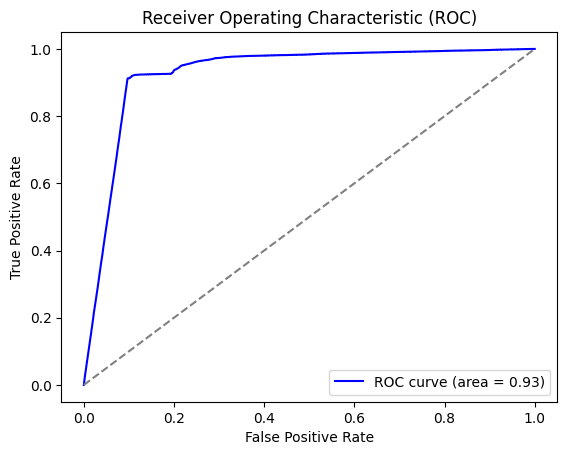

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob_lr)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob_lr)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore=[]

In [ ]:
allRocScore.append(auc_score)
print(allRocScore)

[np.float64(0.9275575923904005)]


<Figure size 1000x1000 with 0 Axes>

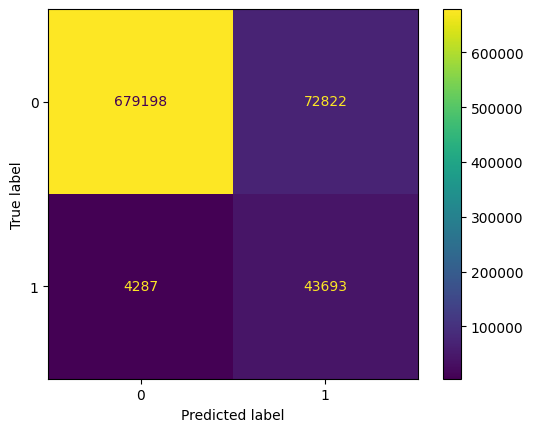

In [ ]:
plt.figure(figsize=(10,10))
dis=ConfusionMatrixDisplay.from_predictions(y_test,lr_pre)
plt.show()

**Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
random=RandomForestClassifier(    n_estimators=10,
    class_weight="balanced",
    max_depth=10,         # Prevents trees from growing infinitely deep
    max_samples=0.1,      # Forces each tree to only look at 10% of the data (320k rows)
    random_state=0,
    n_jobs=-1             # Utilizes all CPU cores for training the trees
                                  )
cv_strategy = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)
cv_scores = cross_val_score(random, X_train_unscale, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
print("Cross-Validation AUC Scores:", cv_scores)
print("Mean AUC Performance:", cv_scores.mean())
random.fit(X_train_unscale,y_train)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Cross-Validation AUC Scores: [0.93419653 0.93493548 0.93571954 0.93544054 0.93484107 0.93467623
 0.93476415 0.93449354]
Mean AUC Performance: 0.934883385251658


RandomForestClassifier(class_weight='balanced', max_depth=10, max_samples=0.1,
                       n_estimators=10, n_jobs=-1, random_state=0)

In [ ]:
random.fit(X_train_unscale,y_train)
ran_pre=random.predict(x_test_unscale)

In [ ]:
y_prob_ran = random.predict_proba(x_test_unscale)[:, 1]

In [ ]:
print(type(f1_score))

<class 'function'>


In [ ]:
from sklearn.metrics import f1_score
CR=classification_report(y_test,ran_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,ran_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,ran_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,ran_pre)
print("precision_score :",precision)
recall=recall_score(y_test,ran_pre)
print("recall_score :",recall)
f1 = f1_score(y_test,ran_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,y_prob_ran)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       1.00      0.90      0.94    752020
           1       0.37      0.97      0.54     47980

    accuracy                           0.90    800000
   macro avg       0.69      0.93      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[674370  77650]
 [  1392  46588]]
accuracy_score : 0.9011975
precision_score : 0.3749899386661086
recall_score : 0.9709879116298458
f1_score : 0.5410351995726347
pr_auc_scores : 0.3691530082714518


ROC AUC: 0.9349


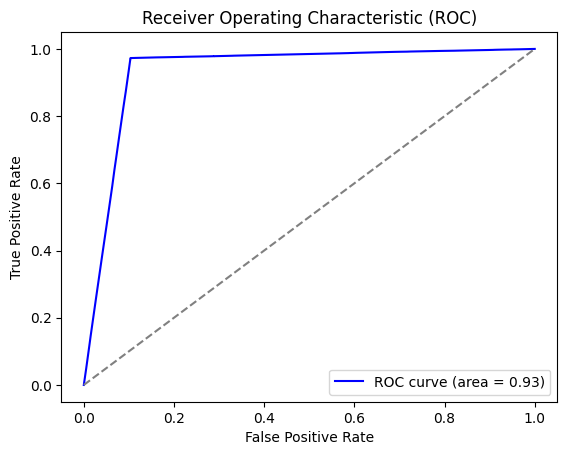

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob_ran)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob_ran)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore.append(auc_score)
print(allRocScore)

[np.float64(0.9275575923904005), np.float64(0.9349264739229673)]


In [ ]:
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
all_f1.append(f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_f1)
all_pr_sc.append(pr_sc)
print(all_pr_sc)

[0.37499892717675837, 0.3749899386661086]
[0.9106502709462276, 0.9709879116298458]
[0.90361375, 0.9011975]
[0.5312380315511109, 0.5410351995726347]
[np.float64(0.3618197600932256), np.float64(0.3691530082714518)]


In [ ]:
model_name.append("RandomForestClassifier")
model_mean.append(random.score(X_train_unscale,y_train))

<Figure size 1000x1000 with 0 Axes>

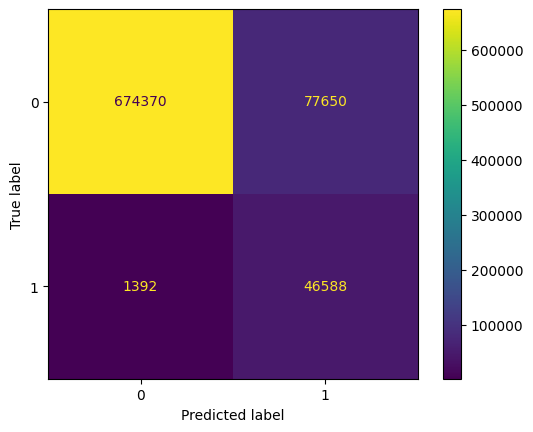

In [ ]:
plt.figure(figsize=(10,10))
dis=ConfusionMatrixDisplay.from_predictions(y_test,ran_pre)
plt.show()

**Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 1. Initialize your Decision Tree model
# (Setting max_depth helps prevent the tree from growing infinitely and crashing memory)
dt_model = DecisionTreeClassifier(max_depth=10,class_weight="balanced", random_state=0)

# 2. Set up Stratified K-Fold for reliable splits
cv_strategy = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)

# 3. Run cross-validation directly on your combined training matrix
# (Using 'roc_auc' or 'accuracy' depending on your metric)
cv_scores = cross_val_score(dt_model, X_train_unscale, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)

print("Cross-Validation AUC Scores:", cv_scores)
print("Mean AUC Performance:", cv_scores.mean())



Cross-Validation AUC Scores: [0.9340717  0.93451293 0.93466712 0.93461548 0.93494868 0.93510489
 0.93469819 0.93459916]
Mean AUC Performance: 0.9346522687832988


In [ ]:
dt_model.fit(X_train_unscale,y_train)
dt_pre=dt_model.predict(x_test_unscale)

In [ ]:
y_prob_dt = dt_model.predict_proba(x_test_unscale)[:, 1]

In [ ]:
model_name.append("DecisionTreeClassifier")
model_mean.append(dt_model.score(X_train_unscale,y_train))

In [ ]:
CR=classification_report(y_test,dt_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,dt_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,dt_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,dt_pre)
print("precision_score :",precision)
recall=recall_score(y_test,dt_pre)
print("recall_score :",recall)
f1=f1_score(y_test,dt_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,y_prob_dt)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       1.00      0.90      0.94    752020
           1       0.37      0.97      0.54     47980

    accuracy                           0.90    800000
   macro avg       0.69      0.93      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[674258  77762]
 [  1339  46641]]
accuracy_score : 0.90112375
precision_score : 0.37491861128750914
recall_score : 0.9720925385577324
f1_score : 0.5411322462191748
pr_auc_scores : 0.36748038586856946


ROC AUC: 0.9342


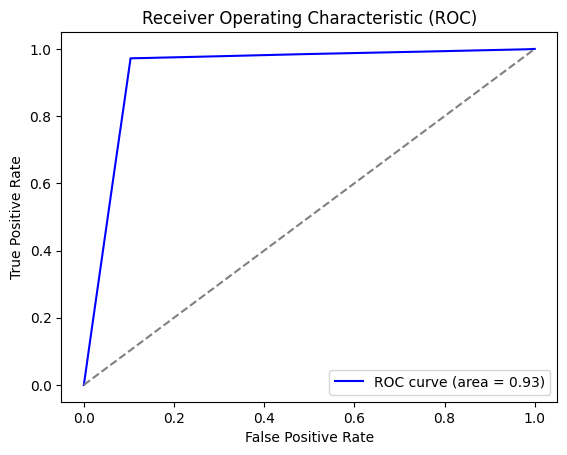

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob_dt)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob_dt)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore.append(auc_score)
print(allRocScore)

[np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355)]


In [ ]:
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
all_f1.append(f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_f1)
all_pr_sc.append(pr_sc)
print(all_pr_sc)

[0.37499892717675837, 0.3749899386661086, 0.37491861128750914]
[0.9106502709462276, 0.9709879116298458, 0.9720925385577324]
[0.90361375, 0.9011975, 0.90112375]
[0.5312380315511109, 0.5410351995726347, 0.5411322462191748]
[np.float64(0.3618197600932256), np.float64(0.3691530082714518), np.float64(0.36748038586856946)]


<Figure size 1000x1000 with 0 Axes>

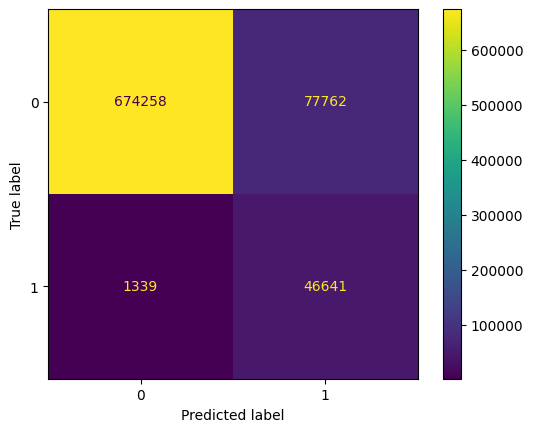

In [ ]:
plt.figure(figsize=(10,10))
dis=ConfusionMatrixDisplay.from_predictions(y_test,dt_pre)
plt.show()

**Naive Bayes**

In [ ]:
from sklearn.naive_bayes import BernoulliNB
naive = BernoulliNB(alpha=1.0)
cv_strategy = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)
cv_scores = cross_val_score(naive, X_train_unscale, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
print("Cross-Validation AUC Scores:", cv_scores)
print("Mean AUC Performance:", cv_scores.mean())

#model.fit(X_train_combined, y_train)

Cross-Validation AUC Scores: [0.91756905 0.91788737 0.91861316 0.91756208 0.91744631 0.91685463
 0.91799904 0.91633404]
Mean AUC Performance: 0.9175332079109141


In [ ]:
naive.fit(X_train_unscale,y_train)
naive_pre=naive.predict(x_test_unscale)

In [ ]:
y_prob_na = naive.predict_proba(x_test_unscale)[:, 1]

In [ ]:
model_name.append("BernoulliNB")
model_mean.append(naive.score(X_train_unscale,y_train))

In [ ]:
CR=classification_report(y_test,naive_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,naive_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,naive_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,naive_pre)
print("precision_score :",precision)
recall=recall_score(y_test,naive_pre)
print("recall_score :",recall)
f1=f1_score(y_test,naive_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,y_prob_na)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       0.99      0.90      0.95    752020
           1       0.38      0.91      0.53     47980

    accuracy                           0.90    800000
   macro avg       0.68      0.91      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[679152  72868]
 [  4254  43726]]
accuracy_score : 0.9035975
precision_score : 0.3750278745046915
recall_score : 0.9113380575239683
f1_score : 0.5313840582352012
pr_auc_scores : 0.354472288685457


ROC AUC: 0.9174


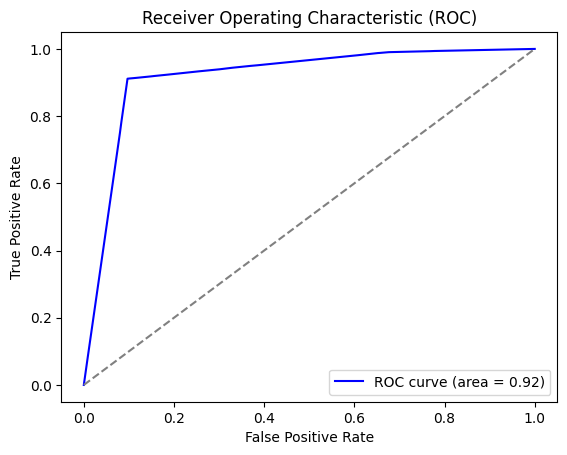

In [ ]:
# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob_na)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob_na)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore.append(auc_score)
print(allRocScore)

[np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355), np.float64(0.9173945396741032)]


In [ ]:
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
all_f1.append(f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_f1)
all_pr_sc.append(pr_sc)
print(all_pr_sc)

[0.37499892717675837, 0.3749899386661086, 0.37491861128750914, 0.3750278745046915]
[0.9106502709462276, 0.9709879116298458, 0.9720925385577324, 0.9113380575239683]
[0.90361375, 0.9011975, 0.90112375, 0.9035975]
[0.5312380315511109, 0.5410351995726347, 0.5411322462191748, 0.5313840582352012]
[np.float64(0.3618197600932256), np.float64(0.3691530082714518), np.float64(0.36748038586856946), np.float64(0.354472288685457)]


<Figure size 1000x1000 with 0 Axes>

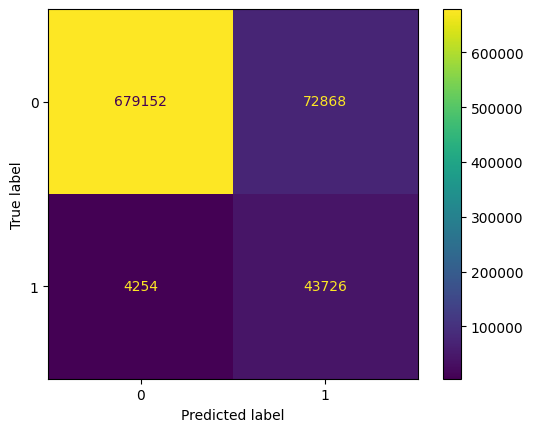

In [ ]:
plt.figure(figsize=(10,10))
dis=ConfusionMatrixDisplay.from_predictions(y_test,naive_pre)
plt.show()

**ExtraTreesClassifier**

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

et_model = ExtraTreesClassifier(
    n_estimators=10,
    max_depth=10,
    class_weight='balanced',
    random_state=0,
    n_jobs=-1
)
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
cv_scores = cross_val_score(et_model, X_train_unscale, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
print("Cross-Validation AUC Scores:", cv_scores)
print("Mean AUC Performance:", cv_scores.mean())

Cross-Validation AUC Scores: [0.92448755 0.92725875 0.9325736 ]
Mean AUC Performance: 0.9281066293242736


In [ ]:
et_model.fit(X_train_unscale,y_train)
et_pre=et_model.predict(x_test_unscale)

In [ ]:
y_prob_et = et_model.predict_proba(x_test_unscale)[:, 1]

In [ ]:
model_name.append("ExtraTreesClassifier")
model_mean.append(et_model.score(X_train_unscale,y_train))

In [ ]:
CR=classification_report(y_test,et_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,et_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,et_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,et_pre)
print("precision_score :",precision)
recall=recall_score(y_test,et_pre)
print("recall_score :",recall)
f1=f1_score(y_test,et_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,y_prob_et)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       0.99      0.90      0.95    752020
           1       0.38      0.91      0.53     47980

    accuracy                           0.90    800000
   macro avg       0.68      0.91      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[679152  72868]
 [  4254  43726]]
accuracy_score : 0.9035975
precision_score : 0.3750278745046915
recall_score : 0.9113380575239683
f1_score : 0.5313840582352012
pr_auc_scores : 0.3585518927895853


ROC AUC: 0.9241


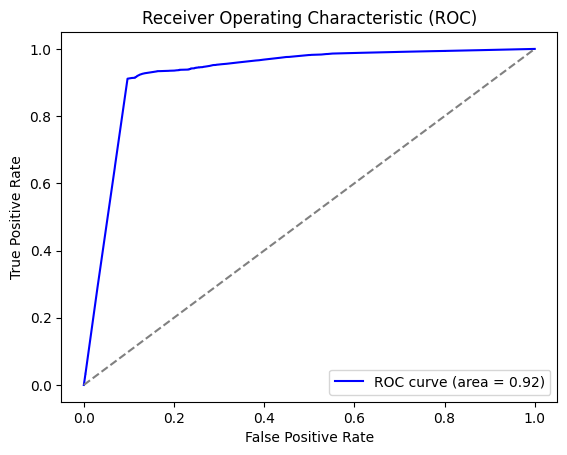

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob_et)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob_et)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore.append(auc_score)
print(allRocScore)

[np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355), np.float64(0.9173945396741032), np.float64(0.924078535527805)]


In [ ]:
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
all_f1.append(f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_f1)
all_pr_sc.append(pr_sc)
print(all_pr_sc)

[0.37499892717675837, 0.3749899386661086, 0.37491861128750914, 0.3750278745046915, 0.3750278745046915]
[0.9106502709462276, 0.9709879116298458, 0.9720925385577324, 0.9113380575239683, 0.9113380575239683]
[0.90361375, 0.9011975, 0.90112375, 0.9035975, 0.9035975]
[0.5312380315511109, 0.5410351995726347, 0.5411322462191748, 0.5313840582352012, 0.5313840582352012]
[np.float64(0.3618197600932256), np.float64(0.3691530082714518), np.float64(0.36748038586856946), np.float64(0.354472288685457), np.float64(0.3585518927895853)]


<Figure size 1000x1000 with 0 Axes>

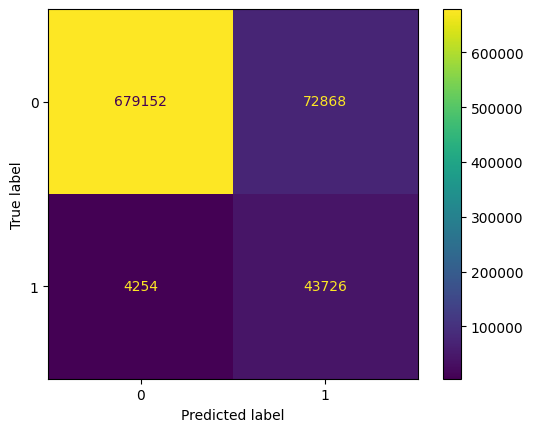

In [ ]:
plt.figure(figsize=(10,10))
dis=ConfusionMatrixDisplay.from_predictions(y_test,et_pre)
plt.show()

In [ ]:
pip install xgboost scikit-learn pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.4/252.4 MB 1.6 MB/s eta 0:00:00


**XGBoost**

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=0,
    n_jobs=-1
)
cv_strategy = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=0
)

In [ ]:
roc_scores = cross_val_score(
    xgb_model,
    X_train_unscale,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)

print("ROC-AUC Scores:", roc_scores)
print("Mean ROC-AUC:", roc_scores.mean())

ROC-AUC Scores: [0.934666   0.93536137 0.93481572 0.93472458]
Mean ROC-AUC: 0.9348919185905324


In [ ]:
xgb_model.fit(X_train_unscale, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_pred = xgb_model.predict(x_test_unscale)
y_prob = xgb_model.predict_proba(x_test_unscale)[:, 1]

In [ ]:
CR=classification_report(y_test,y_pred)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,y_pred)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,y_pred)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,y_pred)
print("precision_score :",precision)
recall=recall_score(y_test,y_pred)
print("recall_score :",recall)
f1=f1_score(y_test,y_pred)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,y_prob)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       1.00      0.90      0.94    752020
           1       0.37      0.97      0.54     47980

    accuracy                           0.90    800000
   macro avg       0.69      0.93      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[673679  78341]
 [  1303  46677]]
accuracy_score : 0.900445
precision_score : 0.37336223583803935
recall_score : 0.972842851187995
f1_score : 0.5396247355460757
pr_auc_scores : 0.368910490948319


ROC AUC: 0.9348


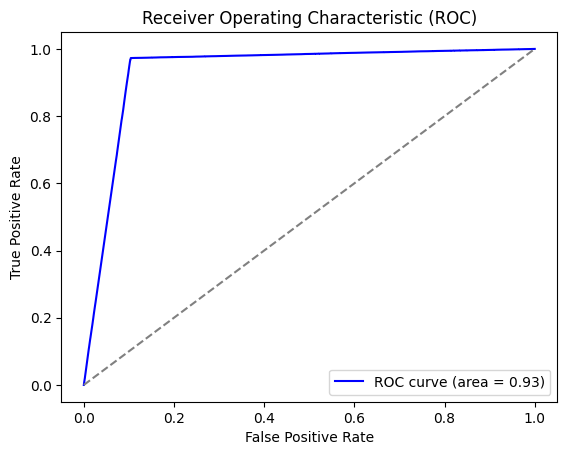

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,y_prob)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,y_prob)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
allRocScore.append(auc_score)
print(allRocScore)
all_precision.append(precision)
all_recall.append(recall)
all_accuracy.append(accuracy)
all_f1.append(f1)
print(all_precision)
print(all_recall)
print(all_accuracy)
print(all_f1)
all_pr_sc.append(pr_sc)
print(all_pr_sc)

[np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355), np.float64(0.9173945396741032), np.float64(0.924078535527805), np.float64(0.9348116980034512)]
[0.37499892717675837, 0.3749899386661086, 0.37491861128750914, 0.3750278745046915, 0.3750278745046915, 0.37336223583803935]
[0.9106502709462276, 0.9709879116298458, 0.9720925385577324, 0.9113380575239683, 0.9113380575239683, 0.972842851187995]
[0.90361375, 0.9011975, 0.90112375, 0.9035975, 0.9035975, 0.900445]
[0.5312380315511109, 0.5410351995726347, 0.5411322462191748, 0.5313840582352012, 0.5313840582352012, 0.5396247355460757]
[np.float64(0.3618197600932256), np.float64(0.3691530082714518), np.float64(0.36748038586856946), np.float64(0.354472288685457), np.float64(0.3585518927895853), np.float64(0.368910490948319)]


In [ ]:
model_name.append("XGBoostClassifier")
model_mean.append(xgb_model.score(X_train_combined,y_train))

# **Length of Models**

Number of models: 6
Number of scores: 6


<BarContainer object of 6 artists>

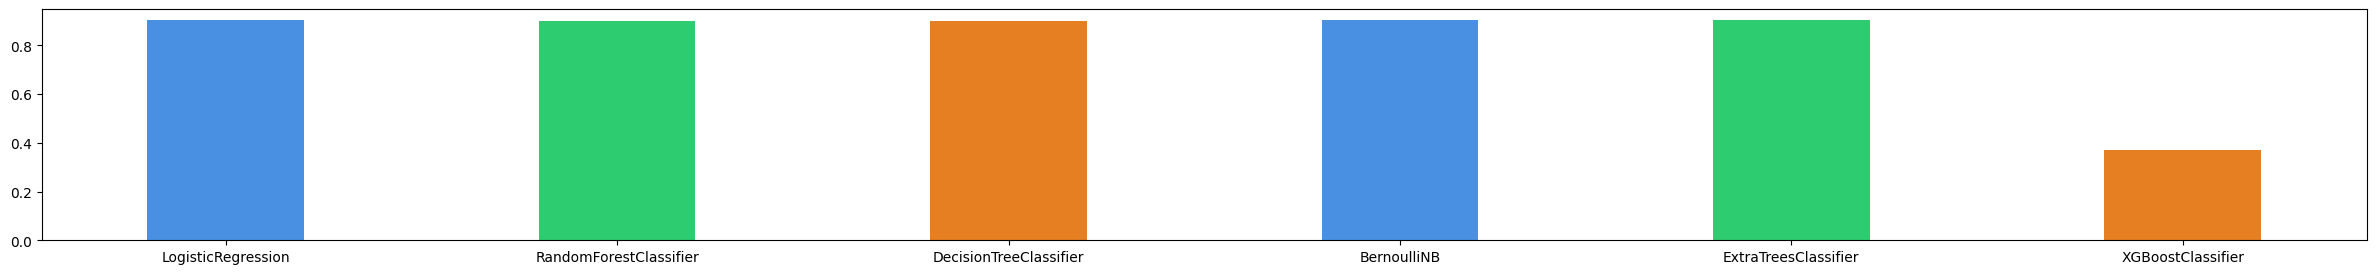

In [ ]:
# CORRECT: Length of both lists must be identical (3 labels, 3 scores)

# Verify matching length before plotting
print(f"Number of models: {len(model_name)}")
print(f"Number of scores: {len(model_mean)}")
plt.figure(figsize=(30,3))
# Now it will plot without any shape mismatch errors!
plt.bar(model_name, model_mean, color=['#4A90E2', '#2ECC71', '#E67E22'], width=0.4,)


# **Comparision of Mean Score with all Models**

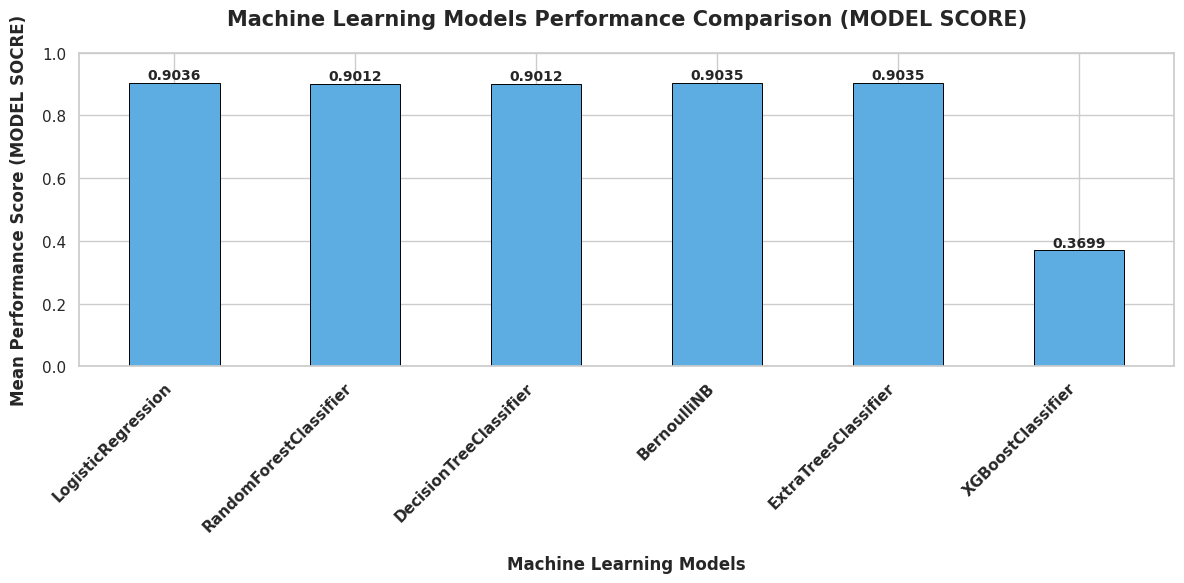

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Apne saare models ka data clean tarah se lock karein

# 3. Figure size ko thoda wide karein (Width=12, Height=6) takay labels ko jagah mile
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid") # Clean layout grid lines

# 4. Custom colors setup karein (Winner models ko alag highlight karne ke liye)
# Pehle 6 models ko light blue aur aakhri 2 winners ko attractive dark green/teal color dein
colors = ['#5DADE2'] * 6 + ['#2E4053'] * 2

# 5. Bar plot generate karein
bars = plt.bar(model_name, model_mean, color=colors, width=0.5, edgecolor='black', linewidth=0.7)

# 6. Title aur Labels set karein
plt.title('Machine Learning Models Performance Comparison (MODEL SCORE)', fontsize=15, fontweight='bold', pad=20)
plt.ylabel('Mean Performance Score (MODEL SOCRE)', fontsize=12, fontweight='bold', labelpad=10)
plt.xlabel('Machine Learning Models', fontsize=12, fontweight='bold', labelpad=15)

# 7. Zoom limits taaki variation saaf dikhe (Jaise aapke excel chart mein tha)
plt.ylim(0, 1)

# =====================================================================
# 🚀 THE MAGIC FIX: LABELS ROTATION AND ALIGNMENT
# =====================================================================
# rotation=45 aur ha='right' karne se text kabhi ek doosre ke upar nahi chadhega
plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='semibold')
plt.yticks(fontsize=11)

# 8. Bars ke upar exact score text lagayein
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        height + 0.002,
        f'{height:.4f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# 9. tight_layout() lagana zaroori hai takay neeche se cut na ho text
plt.tight_layout()
plt.show()


**Comparision of ROC-AUC with all Models**

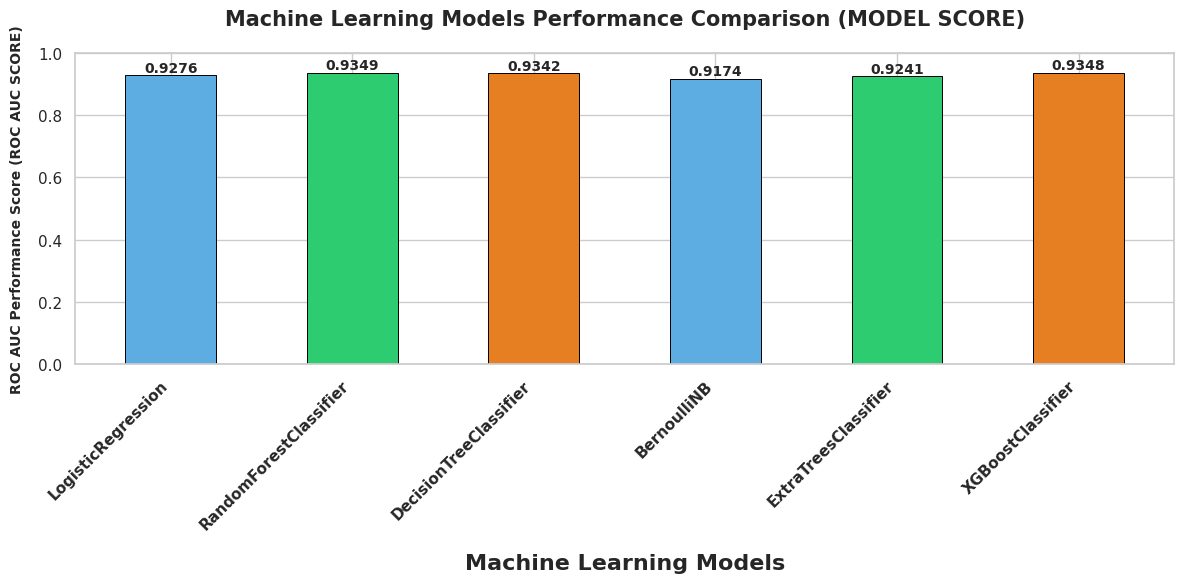

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Apne saare models ka data clean tarah se lock karein

# 3. Figure size ko thoda wide karein (Width=12, Height=6) takay labels ko jagah mile
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid") # Clean layout grid lines

# 4. Custom colors setup karein (Winner models ko alag highlight karne ke liye)
# Pehle 6 models ko light blue aur aakhri 2 winners ko attractive dark green/teal color dein
colors = ['#5DADE2','#2ECC71', '#E67E22'] * 6 + ['#2E4053'] * 2

# 5. Bar plot generate karein
bars = plt.bar(model_name, allRocScore, color=colors, width=0.5, edgecolor='black', linewidth=0.7)

# 6. Title aur Labels set karein
plt.title('Machine Learning Models Performance Comparison (MODEL SCORE)', fontsize=15, fontweight='bold', pad=20)
plt.ylabel('ROC AUC Performance Score (ROC AUC SCORE)', fontsize=10, fontweight='bold', labelpad=10)
plt.xlabel('Machine Learning Models', fontsize=16, fontweight='bold', labelpad=15)

# 7. Zoom limits taaki variation saaf dikhe (Jaise aapke excel chart mein tha)
plt.ylim(0, 1)

# =====================================================================
# 🚀 THE MAGIC FIX: LABELS ROTATION AND ALIGNMENT
# =====================================================================
# rotation=45 aur ha='right' karne se text kabhi ek doosre ke upar nahi chadhega
plt.xticks(rotation=45, ha='right', fontsize=11, fontweight='semibold')
plt.yticks(fontsize=11)

# 8. Bars ke upar exact score text lagayein
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        height + 0.002,
        f'{height:.4f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# 9. tight_layout() lagana zaroori hai takay neeche se cut na ho text
plt.tight_layout()
plt.show()


In [ ]:
print("Models:", len(model_name))
print("ROC Scores:", len(allRocScore))
print("Colors:", len(colors))

print(model_name)
print(allRocScore)


Models: 6
ROC Scores: 6
Colors: 20
['LogisticRegression', 'RandomForestClassifier', 'DecisionTreeClassifier', 'BernoulliNB', 'ExtraTreesClassifier', 'XGBoostClassifier']
[np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355), np.float64(0.9173945396741032), np.float64(0.924078535527805), np.float64(0.9348116980034512)]


In [ ]:
for i, score in enumerate(allRocScore):
    print(i, score)

0 0.9275575923904005
1 0.9349264739229673
2 0.9342410337004355
3 0.9173945396741032
4 0.924078535527805
5 0.9348116980034512


In [ ]:
for i, name in enumerate(model_name):
    print(i, name)


0 LogisticRegression
1 RandomForestClassifier
2 DecisionTreeClassifier
3 BernoulliNB
4 ExtraTreesClassifier
5 XGBoostClassifier


In [ ]:
model_results = {
    "Precision": all_precision,
    "Recall": all_recall,
    "Accuracy": all_accuracy,
    "F1": all_f1,
    "ROC-AUC": allRocScore,
    "PR-AUC": all_pr_sc
}
print(model_results)

{'Precision': [0.37499892717675837, 0.3749899386661086, 0.37491861128750914, 0.3750278745046915, 0.3750278745046915, 0.37336223583803935], 'Recall': [0.9106502709462276, 0.9709879116298458, 0.9720925385577324, 0.9113380575239683, 0.9113380575239683, 0.972842851187995], 'Accuracy': [0.90361375, 0.9011975, 0.90112375, 0.9035975, 0.9035975, 0.900445], 'F1': [0.5312380315511109, 0.5410351995726347, 0.5411322462191748, 0.5313840582352012, 0.5313840582352012, 0.5396247355460757], 'ROC-AUC': [np.float64(0.9275575923904005), np.float64(0.9349264739229673), np.float64(0.9342410337004355), np.float64(0.9173945396741032), np.float64(0.924078535527805), np.float64(0.9348116980034512)], 'PR-AUC': [np.float64(0.3618197600932256), np.float64(0.3691530082714518), np.float64(0.36748038586856946), np.float64(0.354472288685457), np.float64(0.3585518927895853), np.float64(0.368910490948319)]}


In [ ]:
print("Models:", len(model_name))
print("Precision:", len(all_precision))
print("Recall:", len(all_recall))
print("F1:", len(all_f1))
print("ROC-AUC:", len(allRocScore))
print("PR-AUC:", len(all_pr_sc))

Models: 6
Precision: 6
Recall: 6
F1: 6
ROC-AUC: 6
PR-AUC: 6


**Report of all Models**

In [ ]:
results_df = pd.DataFrame({
    "Model": model_name,
    "Precision": all_precision,
    "Recall": all_recall,
    "F1": all_f1,
    "ROC-AUC": allRocScore,
    "PR-AUC": all_pr_sc,
    "model_mean":model_mean
})

In [ ]:
print(results_df)

                    Model  Precision    Recall        F1   ROC-AUC    PR-AUC  \
0      LogisticRegression   0.374999  0.910650  0.531238  0.927558  0.361820   
1  RandomForestClassifier   0.374990  0.970988  0.541035  0.934926  0.369153   
2  DecisionTreeClassifier   0.374919  0.972093  0.541132  0.934241  0.367480   
3             BernoulliNB   0.375028  0.911338  0.531384  0.917395  0.354472   
4    ExtraTreesClassifier   0.375028  0.911338  0.531384  0.924079  0.358552   
5       XGBoostClassifier   0.373362  0.972843  0.539625  0.934812  0.368910   

   model_mean  
0    0.903562  
1    0.901223  
2    0.901206  
3    0.903530  
4    0.903530  
5    0.369942  


**Distribution**

In [ ]:
print("Actual test distribution:")
print(y_test.value_counts())

print("\nActual test proportions:")
print(y_test.value_counts(normalize=True))

Actual test distribution:
churn_30d
0    752020
1     47980
Name: count, dtype: int64

Actual test proportions:
churn_30d
0    0.940025
1    0.059975
Name: proportion, dtype: float64


**Prediction Distribution of Every Model**

In [ ]:
print("Logistic Regression:")
print(pd.Series(lr_pre).value_counts())

print("\nRandom Forest:")
print(pd.Series(ran_pre).value_counts())

print("\nDecision Tree:")
print(pd.Series(dt_pre).value_counts())

print("\nBernoulliNB:")
print(pd.Series(naive_pre).value_counts())

print("\nExtra Trees:")
print(pd.Series(et_pre).value_counts())

print("\nXGBoost:")
print(pd.Series(y_pred).value_counts())

Logistic Regression:
0    683485
1    116515
Name: count, dtype: int64

Random Forest:
0    675762
1    124238
Name: count, dtype: int64

Decision Tree:
0    675597
1    124403
Name: count, dtype: int64

BernoulliNB:
0    683406
1    116594
Name: count, dtype: int64

Extra Trees:
0    683406
1    116594
Name: count, dtype: int64

XGBoost:
0    674982
1    125018
Name: count, dtype: int64


**Confusion Matrix of Every Model**

In [ ]:
from sklearn.metrics import confusion_matrix

models_predictions = {
    "Logistic Regression": lr_pre,
    "Random Forest": ran_pre,
    "Decision Tree": dt_pre,
    "BernoulliNB": naive_pre,
    "Extra Trees": et_pre,
    "XGBoost": y_pred
}

for name, pred in models_predictions.items():
    print(f"\n{name}")
    print(confusion_matrix(y_test, pred))


Logistic Regression
[[679198  72822]
 [  4287  43693]]

Random Forest
[[674370  77650]
 [  1392  46588]]

Decision Tree
[[674258  77762]
 [  1339  46641]]

BernoulliNB
[[679152  72868]
 [  4254  43726]]

Extra Trees
[[679152  72868]
 [  4254  43726]]

XGBoost
[[673679  78341]
 [  1303  46677]]


In [ ]:
lr_pred = lr_model.predict(x_test_combined)
rf_pred = random.predict(x_test_unscale)
dt_pred = dt_model.predict(x_test_unscale)
nb_pred = naive.predict(x_test_combined)
et_pred = et_model.predict(x_test_unscale)
xgb_pred = xgb_model.predict(x_test_unscale)

In [ ]:
lr_precision = precision_score(y_test, lr_pred)
rf_precision = precision_score(y_test, rf_pred)
dt_precision = precision_score(y_test, dt_pred)
nb_precision = precision_score(y_test, nb_pred)
et_precision = precision_score(y_test, et_pred)
xgb_precision = precision_score(y_test, xgb_pred)

In [ ]:
print("LR vs RF:", np.array_equal(lr_pred, rf_pred))
print("LR vs DT:", np.array_equal(lr_pred, dt_pred))
print("LR vs NB:", np.array_equal(lr_pred, nb_pred))
print("LR vs ET:", np.array_equal(lr_pred, et_pred))
print("LR vs XGB:", np.array_equal(lr_pred, xgb_pred))

LR vs RF: False
LR vs DT: False
LR vs NB: False
LR vs ET: False
LR vs XGB: False


In [ ]:
for name, pred in models_predictions.items():
    print(
        name,
        "Predicted churn =",
        (pred == 1).sum(),
        "| Total =",
        len(pred)
    )

Logistic Regression Predicted churn = 116515 | Total = 800000
Random Forest Predicted churn = 124238 | Total = 800000
Decision Tree Predicted churn = 124403 | Total = 800000
BernoulliNB Predicted churn = 116594 | Total = 800000
Extra Trees Predicted churn = 116594 | Total = 800000
XGBoost Predicted churn = 125018 | Total = 800000


**Distribution on the based of Probility**

In [ ]:
xgb_prob = xgb_model.predict_proba(x_test_combined)[:, 1]

print("Minimum probability:", xgb_prob.min())
print("Maximum probability:", xgb_prob.max())
print("Mean probability:", xgb_prob.mean())

Minimum probability: 0.006619323
Maximum probability: 0.91836184
Mean probability: 0.6242054


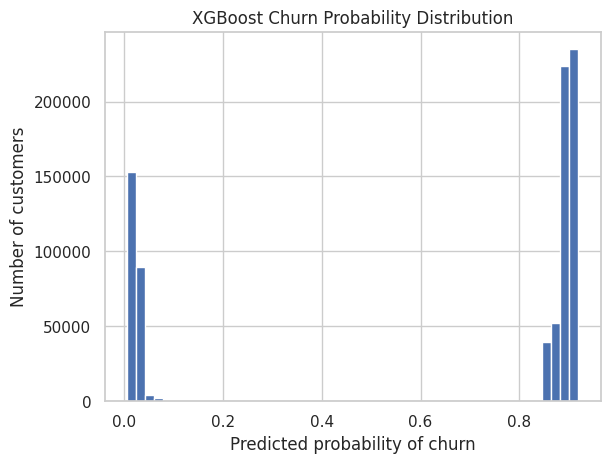

In [ ]:
import matplotlib.pyplot as plt

plt.hist(xgb_prob, bins=50)
plt.xlabel("Predicted probability of churn")
plt.ylabel("Number of customers")
plt.title("XGBoost Churn Probability Distribution")
plt.show()

In [ ]:
# Get row indices for each class
negative_idx = np.where(np.asarray(y_train) == 0)[0]
positive_idx = np.where(np.asarray(y_train) == 1)[0]

# Number of samples per class
samples_per_class = 180_000

# Randomly select equal samples
rng = np.random.default_rng(0)

negative_sample = rng.choice(
    negative_idx,
    size=samples_per_class,
    replace=False
)

positive_sample = rng.choice(
    positive_idx,
    size=samples_per_class,
    replace=False
)

# Combine indices
tune_idx = np.concatenate([
    negative_sample,
    positive_sample
])

# Shuffle the combined indices
rng.shuffle(tune_idx)

# Create balanced tuning data
X_tune = X_train_unscale[tune_idx]

if hasattr(y_train, "iloc"):
    y_tune = y_train.iloc[tune_idx]
else:
    y_tune = y_train[tune_idx]

print("Tuning shape:", X_tune.shape)
print("Target distribution:")
print(pd.Series(y_tune).value_counts())

Tuning shape: (360000, 19)
Target distribution:
churn_30d
1    180000
0    180000
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

rf_model = RandomForestClassifier(
    n_estimators=50,
    class_weight=None,
    random_state=0,
    n_jobs=-1
)

param_dist_rf = {
    "max_depth": [5, 10, 15],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

cv_tune = StratifiedKFold(
    n_splits=8,
    shuffle=True,
    random_state=0
)

rf_random_search = RandomizedSearchCV(
    rf_model,
    param_distributions=param_dist_rf,
    n_iter=4,
    scoring="f1",
    cv=cv_tune,
    random_state=0,
    n_jobs=-1,
    verbose=2,
    refit=True
)

rf_random_search.fit(X_tune, y_tune)

Fitting 8 folds for each of 4 candidates, totalling 32 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=8, random_state=0, shuffle=True),
                   estimator=RandomForestClassifier(n_estimators=50, n_jobs=-1,
                                                    random_state=0),
                   n_iter=4, n_jobs=-1,
                   param_distributions={'max_depth': [5, 10, 15],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5]},
                   random_state=0, scoring='f1', verbose=2)

In [ ]:
print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV F1:")
print(rf_random_search.best_score_)

Best Parameters:
{'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}

Best CV F1:
0.9376546382489983


In [ ]:
best_params = rf_random_search.best_params_

final_rf = RandomForestClassifier(
    **best_params,
    n_estimators=100,
    class_weight="balanced",
    random_state=0,
    n_jobs=-1
)

final_rf.fit(
    X_train_unscale,
    y_train
)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5, n_jobs=-1,
                       random_state=0)

In [ ]:
rf_pre=final_rf.predict(x_test_unscale)

In [ ]:
rf_pro=final_rf.predict_proba(x_test_unscale)[:,1]

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Your class imbalance ratio
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=0,
    n_jobs=-1
)

param_dist = {
    "n_estimators": [50, 100, 150],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

cv_strategy = StratifiedKFold(
    n_splits=8,
    shuffle=True,
    random_state=0
)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=5,
    scoring="f1",
    cv=cv_tune,
    verbose=2,
    random_state=0,
    n_jobs=-1,
    refit=True
)



In [ ]:
random_search.fit(X_tune, y_tune)

Fitting 8 folds for each of 5 candidates, totalling 40 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=8, random_state=0, shuffle=True),
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           g...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=-1,
                                           num_parallel_tree=None, ...),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 1.0],
                                        'learning_rate': [0.03, 0.05, 0.1],
                                        'max_depth': [3, 5, 7, 9],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [50, 100, 150],
                                        'subsample': [0.7, 0.8, 1.0]},
                   random_state=0, scoring='f1', verbose=2)

In [ ]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV F1:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 0.7, 'n_estimators': 50, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}

Best CV F1:
0.9376171600627219


In [ ]:
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

best_params = random_search.best_params_

final_xgb = XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=0,
    n_jobs=-1
)

final_xgb.fit(
    X_train_unscale,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=3, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=50, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
xg_pre=random_search.predict(x_test_unscale)

In [ ]:
xg_prob=random_search.predict_proba(x_test_unscale)[:,1]

In [ ]:
print(confusion_matrix(y_test,xg_pre))

[[674188  77832]
 [  1304  46676]]


In [ ]:
CR=classification_report(y_test,xg_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,xg_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,xg_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,xg_pre)
print("precision_score :",precision)
recall=recall_score(y_test,xg_pre)
print("recall_score :",recall)
f1=f1_score(y_test,xg_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,xg_prob)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       1.00      0.90      0.94    752020
           1       0.37      0.97      0.54     47980

    accuracy                           0.90    800000
   macro avg       0.69      0.93      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[674188  77832]
 [  1304  46676]]
accuracy_score : 0.90108
precision_score : 0.3748835416198156
recall_score : 0.9728220091704877
f1_score : 0.5412086637911043
pr_auc_scores : 0.36890971812582996


In [ ]:
CR=classification_report(y_test,rf_pre)
print("classification_report :")
print(CR)
cm=confusion_matrix(y_test,rf_pre)
print("confusion_matrix :")
print(cm)
accuracy=accuracy_score(y_test,rf_pre)
print("accuracy_score :",accuracy)
precision=precision_score(y_test,rf_pre)
print("precision_score :",precision)
recall=recall_score(y_test,rf_pre)
print("recall_score :",recall)
f1=f1_score(y_test,rf_pre)
print("f1_score :",f1)
pr_sc=average_precision_score(y_test,rf_pro)
print("pr_auc_scores :",pr_sc)

classification_report :
              precision    recall  f1-score   support

           0       1.00      0.90      0.94    752020
           1       0.38      0.97      0.54     47980

    accuracy                           0.90    800000
   macro avg       0.69      0.93      0.74    800000
weighted avg       0.96      0.90      0.92    800000

confusion_matrix :
[[674237  77783]
 [  1308  46672]]
accuracy_score : 0.90113625
precision_score : 0.3750110481700213
recall_score : 0.9727386411004585
f1_score : 0.5413286165801606
pr_auc_scores : 0.371918277998374


ROC AUC: 0.9350


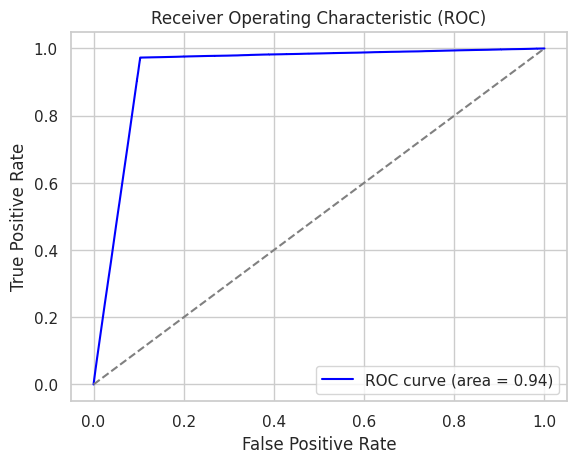

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,rf_pro)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,rf_pro)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


ROC AUC: 0.9344


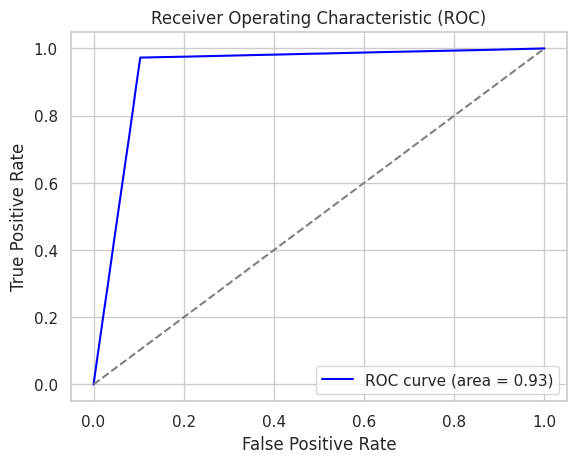

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

# Calculate ROC AUC Score
auc_score = roc_auc_score(y_test,xg_prob)
print(f"ROC AUC: {auc_score:.4f}")

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test,xg_prob)

# Plotting the ROC curve
plt.figure()
plt.plot(
    fpr, tpr, color="blue", label=f"ROC curve (area = {auc_score:.2f})"
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()


In [ ]:
pr_sc=average_precision_score(y_test,y_prob_et)
print("pr_auc_scores :",pr_sc)

pr_auc_scores : 0.3585518927895853


In [ ]:
importance = pd.Series(
    final_rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(20))

transaction_type_airtime        0.416961
kyc_tier_tier1                  0.139470
kyc_tier_tier2                  0.108775
amount_ngn                      0.104155
balance_after_ngn               0.098908
transaction_type_p2p_receive    0.041861
transaction_type_p2p_send       0.032021
transaction_type_billpay        0.023153
transaction_type_cashin         0.013830
kyc_tier_tier3                  0.010447
transaction_type_cashout        0.007001
transaction_type_data           0.003187
device_os_feature_phone         0.000039
device_os_android               0.000038
channel_app                     0.000034
channel_agent                   0.000034
device_os_ios                   0.000030
channel_ussd                    0.000030
channel_web                     0.000026
dtype: float64


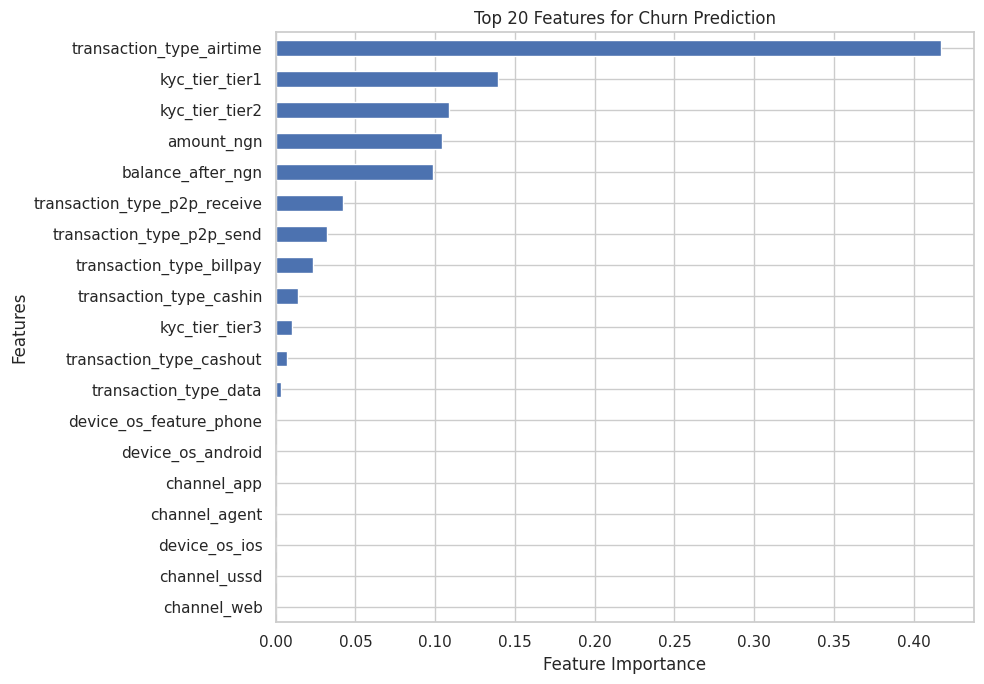

In [ ]:
top20 = importance.head(20).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
top20.plot(kind="barh")

plt.title("Top 20 Features for Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

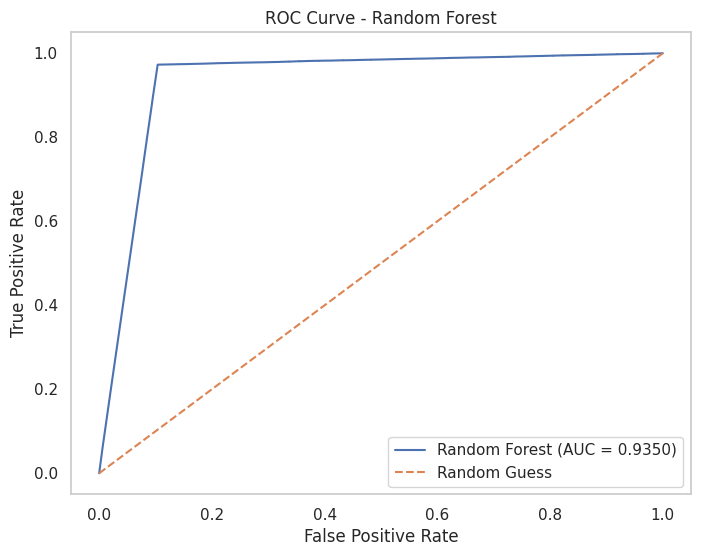

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Final predictions/probabilities
rf_test_prob = final_rf.predict_proba(x_test_unscale)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    rf_test_prob
)

roc_auc = roc_auc_score(
    y_test,
    rf_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

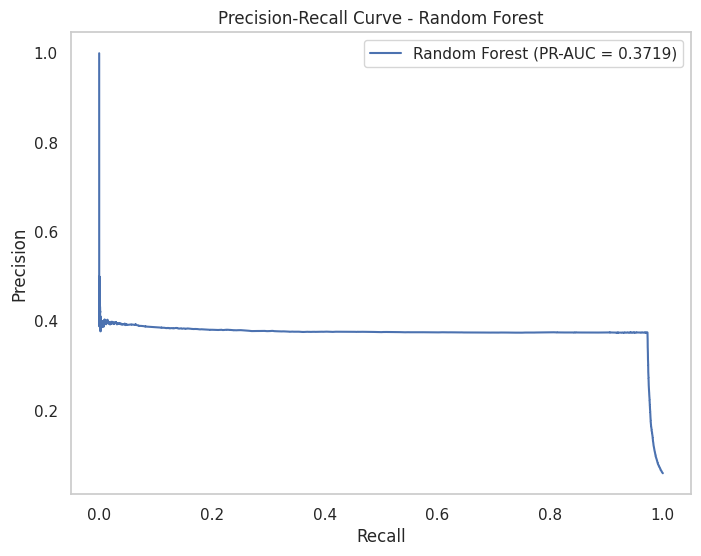

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test,
    rf_test_prob
)

pr_auc = average_precision_score(
    y_test,
    rf_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Random Forest (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

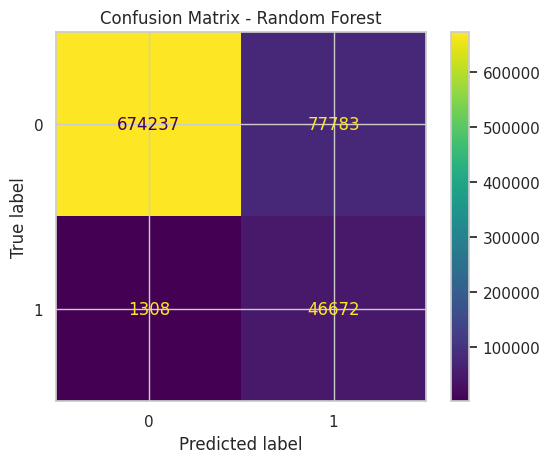

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

rf_test_pred = final_rf.predict(x_test_unscale)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_pred
)

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
import joblib

joblib.dump(
    final_rf,
    "final_random_forest_churn_model.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [ ]:
joblib.dump(
    StandardScaler,
    "standard_scaler.pkl"
)

joblib.dump(
    onehotencoder,
    "onehot_encoder.pkl"
)

print("Scaler and Encoder saved successfully.")

Scaler and Encoder saved successfully.


In [ ]:
from google.colab import files

files.download("final_random_forest_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("standard_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("onehot_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile

files_to_zip = [
    "final_random_forest_churn_model.pkl",
    "standard_scaler.pkl",
    "onehot_encoder.pkl"
]

with zipfile.ZipFile("churn_model_files.zip", "w") as zipf:
    for file in files_to_zip:
        zipf.write(file)

print("ZIP created successfully.")

ZIP created successfully.


In [ ]:
from google.colab import files

files.download("churn_model_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>